-   1.开场串联+11.4复盘
    -   1.1开场三问
        -   1.1.1昨天（11/4）学了什么？今天和它什么关系？
            -   昨天拿到了BUS_BRA的数据，三点滑动平均。昨天从读现成数据，第一次到自己造数据+自己波束出图
        -   1.1.2今天这块在整条项目链的哪个位置？
            -   超声重建链，【今天：RF数据→波束形成DAS→包络→对数压缩→B-Mode图】→DL重建→高质量图
            -   今天的部分就是产出低质量B图
        -   1.1.3今天学完，我能多做哪一件具体的事
            -   ①用numpy造成散射体、生成每个阵元的接收信号
            -   ②手写DAS时延求和，出一张B超图
            -   ③说出为什么三社体是亮点、别处是暗点和阵元数变少分辨率会如何？
    -   1.2复盘
        -   1.2.1三点滑动平均两端点怎么处理？
            -   两个端点旁边没有完整邻居点，需要约定：只算完整窗的点（输出变短）或边界补零（等长）
        -   1.2.2方向三层分别是什么、哪个没定？
            -   赛道（医疗影像/超声AI） 方向：成像重建 课题（地基四块学完商量定）
        -   1.2.3BUS-BRA 现在是什么定位？
            -   练手.已经收尾，不训练分类器，不再扩展；主线切到超声重建

-   2.主任务：点散射体仿真+DAS波束形成
    -   2.1 物理直觉
        -   超声B超图：探头发出一个声波脉冲→声波进入人体组织，碰到组织里一个个小散射体反射回来→探头上各个阵元记录下回波→用一个散射的回波到达不同阵元的时间不同（因为距离不同）→波束形成：对于空间内的每一个点（可以理解为某个一器官的某一个点），将各个阵元按照该点的时延对齐后相加→成像
        -   对于有散射体的地方，各阵元对齐了，相干叠加变亮；对于没有散射体的地方，时延无法对齐，相互抵消变暗。将每一个图都算一遍，就能得到B超图
        -   一些定义
            -   点散射体：将组织简化成若干发光点，每个点有位置(x,z)和反射强度A，是仿真中最基础的模型；真实组织是连续散射，点的模型足以理解成像原理
            -   阵元(element):探头上一排小换能器中的一个
            -   平面波发射:所有阵元同时发射同一个脉冲
            -   DAS(Delay and sum)：先算时延，再求和，波束形成最基础的方法
            -   时延τ:声波发射时间+到达目标点的时间+反射回某个阵元的时间

-   2.2第一步：生成每个阵元的接收信号(RF)

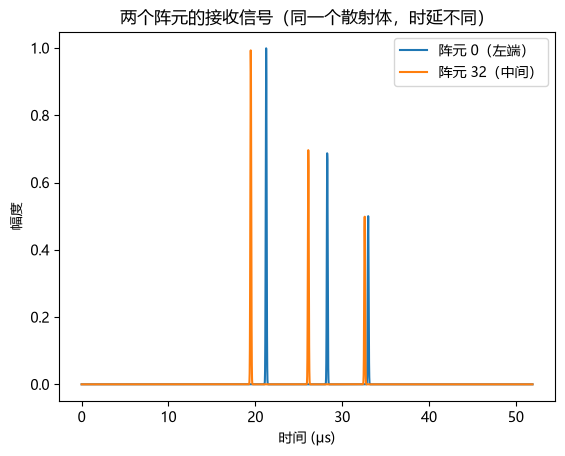

(64, 2078)


In [15]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# ===== 1. 参数 =====
c = 1540.0          # 声速 (m/s)
fs = 40e6           # 采样率 40 MHz
N = 64              # 阵元数
pitch = 0.3e-3      # 阵元间距 0.3 mm（约一个波长）
sigma = 0.05e-6     # 发射脉冲的高斯宽度 50 ns

# ===== 2. 阵元位置（沿 x 轴，中心在原点）=====
elem_x = (np.arange(N) - (N - 1) / 2) * pitch          # shape (N,)

# ===== 3. 散射体 [x(m), z(m), 强度] =====
scatterers = np.array([
    [ 0.0e-3, 15e-3, 1.0],
    [ 3.0e-3, 20e-3, 0.7],
    [-3.0e-3, 25e-3, 0.5],
])

# ===== 4. 接收时间轴（覆盖最远散射体往返）=====
z_max = 40e-3
t_axis = np.arange(0, 2 * z_max / c, 1 / fs)          # shape (T,)

# ===== 5. 生成每个阵元的接收信号 =====
rf = np.zeros((N, len(t_axis)))
for xk, zk, amp in scatterers:
    for i in range(N):
        tau = (zk + np.sqrt((xk - elem_x[i]) ** 2 + zk ** 2)) / c
        rf[i] += amp * np.exp(-((t_axis - tau) ** 2) / (2 * sigma ** 2))

# 看一眼两个阵元的信号：不同阵元，回波到达时间不一样
plt.figure()
plt.plot(t_axis * 1e6, rf[0], label="阵元 0（左端）")
plt.plot(t_axis * 1e6, rf[N // 2], label=f"阵元 {N // 2}（中间）")
plt.xlabel("时间 (μs)"); plt.ylabel("幅度"); plt.legend()
plt.title("两个阵元的接收信号（同一个散射体，时延不同）")
plt.show()
print(rf.shape)

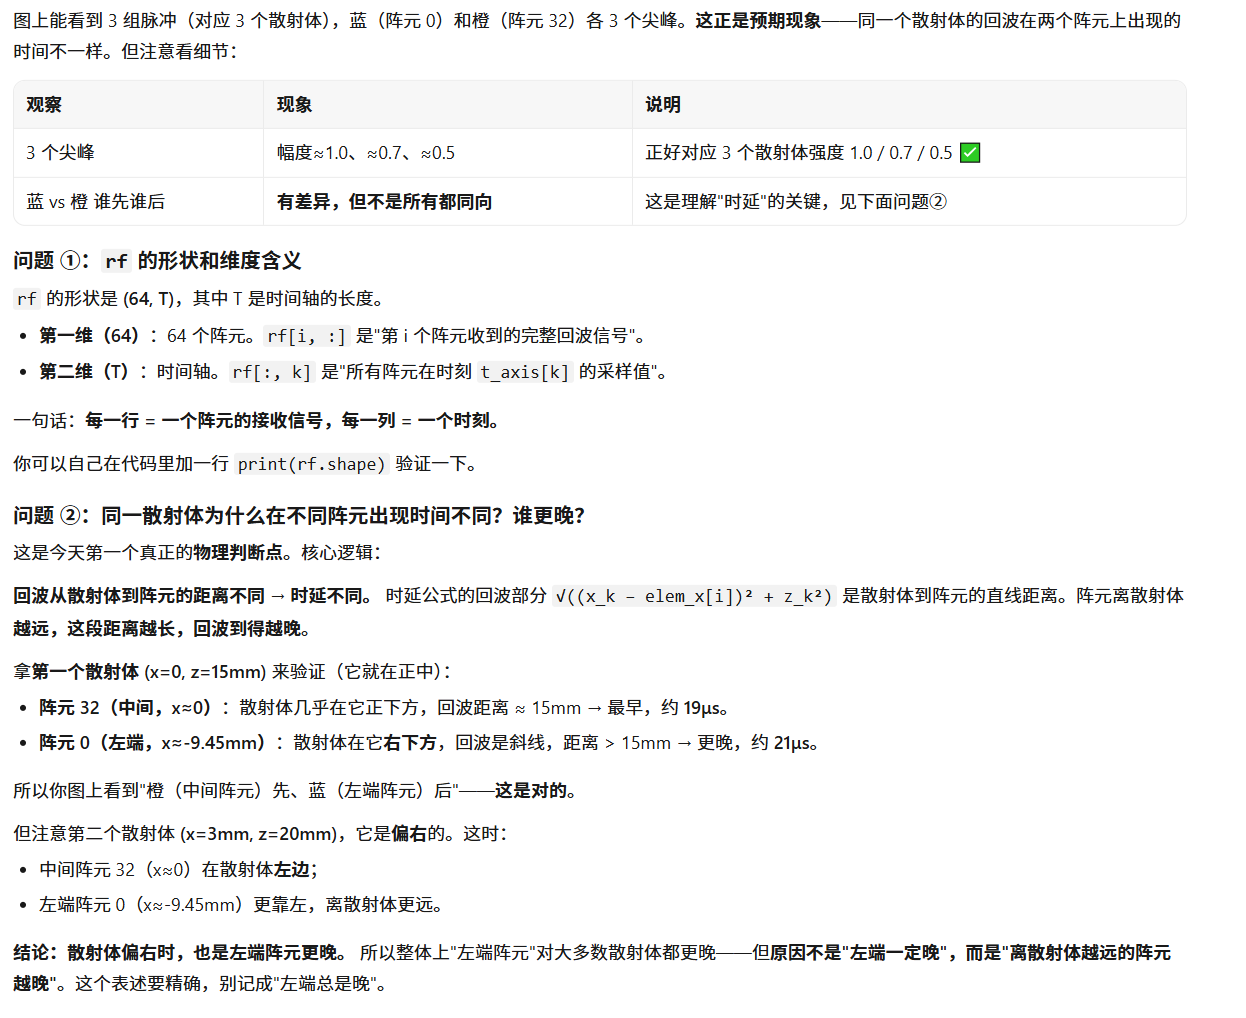

-   2.3第二步：DAS波束形成
    -   对成像网格中每个像素(x,z)，算它对每一个阵元的时延，将各阵元在该时延的值加起来，得到像素强度
        -   具体做法
            -   假设这个点有散射体，算出它到每一个阵元的时延τ
            -   去每个一个阵元中按照τ时延时刻取出值
            -   将所有阵元中的值加起来，作为这个像素的强度
        -   有散射体，就相干叠加，亮；没有散射体，按照这个时刻来取的值有正有负，加起来互相抵消，暗
    -   DAS的精髓就是：先按几何时延dalay对齐，再求和，真有散射体就变亮


In [16]:
# ===== 6. DAS 波束形成（朴素三重循环，理解用）=====
nx, nz = 256, 512                     # 成像网格：横向 256 点、纵向 512 点
x_grid = np.linspace(-10e-3, 10e-3, nx)   # x 方向：-10mm ~ +10mm
z_grid = np.linspace(2e-3, 40e-3, nz)     # z 方向：2mm ~ 40mm（深度）

image = np.zeros((nz, nx))            # 输出 B 图，形状 (nz, nx) = (512, 256)
for j, z in enumerate(z_grid):        # 遍历每一行（深度）
    for i_idx, x in enumerate(x_grid):# 遍历每一列（横向）
        s = 0.0
        for i in range(N):            # 对每个阵元，取 τ 时刻的值累加
            tau = (z + np.sqrt((x - elem_x[i]) ** 2 + z ** 2)) / c
            k = int(round(tau * fs))  # 把时延换算成采样点下标
            if 0 <= k < len(t_axis):  # 防越界
                s += rf[i, k]
        image[j, i_idx] = s           # 该像素强度 = 64 阵元求和


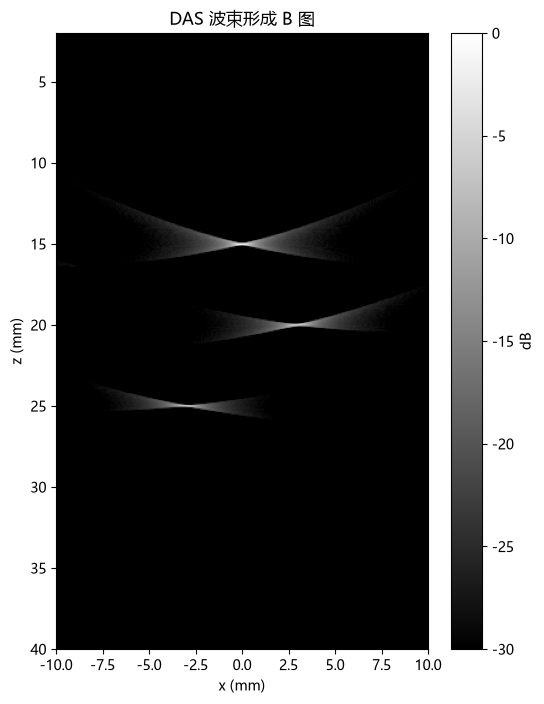

In [17]:
# ===== 7. 显示（对数压缩，超声常用）=====
disp = np.abs(image)                              # 取绝对值（信号有正有负）
disp_db = 20 * np.log10(disp / disp.max() + 1e-6) # 转成 dB，超声动态范围大

plt.figure(figsize=(6, 8))
plt.imshow(disp_db,
           extent=[x_grid[0]*1e3, x_grid[-1]*1e3, z_grid[-1]*1e3, z_grid[0]*1e3],
           cmap="gray", aspect="auto", vmin=-30, vmax=0)
plt.colorbar(label="dB")
plt.xlabel("x (mm)"); plt.ylabel("z (mm)")
plt.title("DAS 波束形成 B 图")
plt.show()


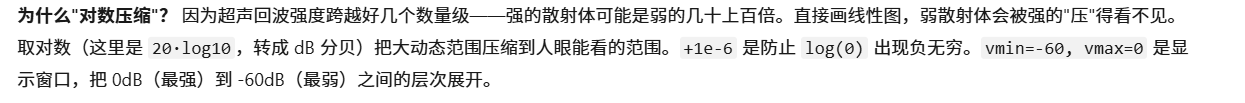
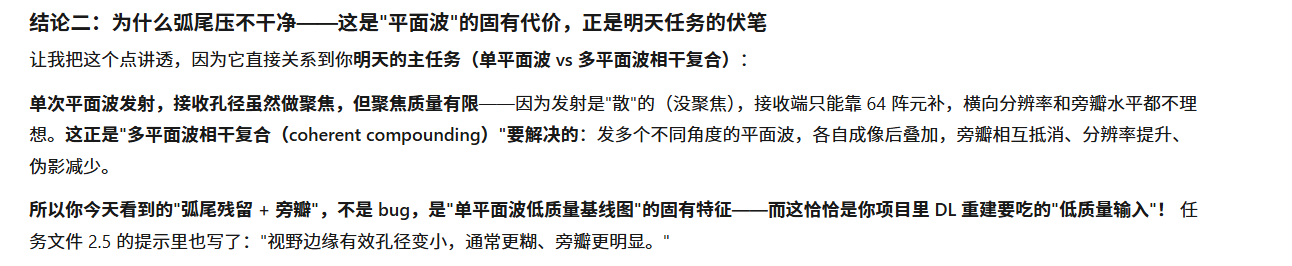
这就是我上一条说的"单平面波发射 + 有限孔径"的固有代价：横向分辨率不够 + 旁瓣残留

-   2.5变式
    -   变式1：
        -   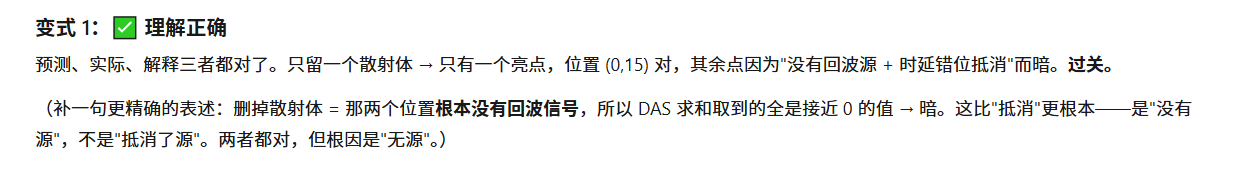
    -   变式2：
        -   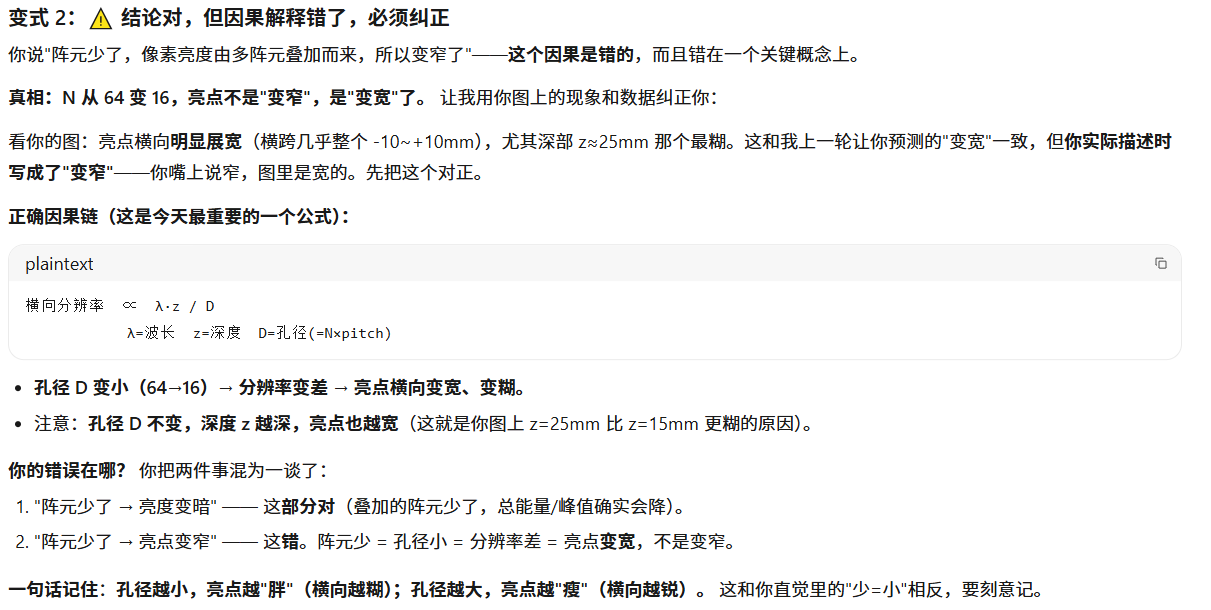
    -   变式3：
        -   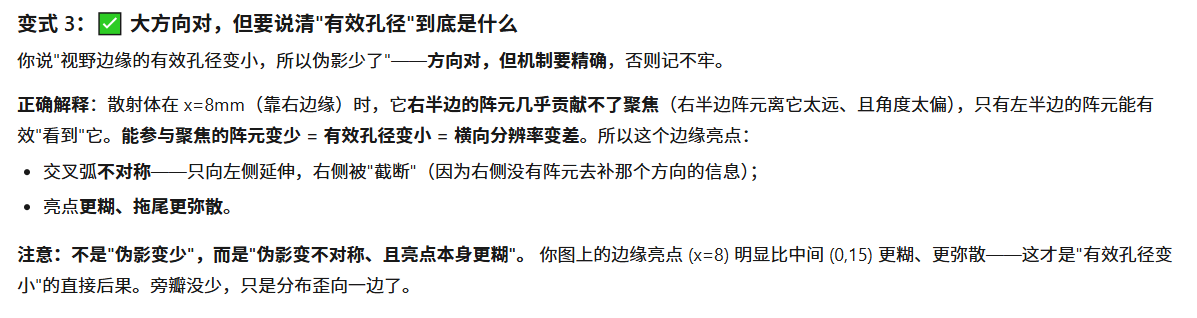
        -   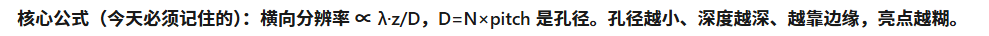
        -   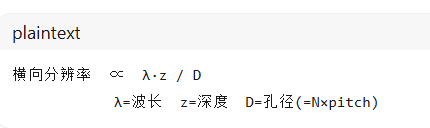
        -   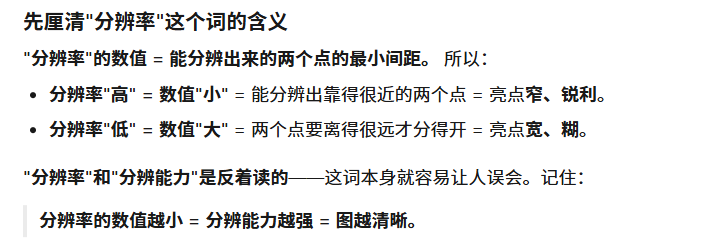
        -   分辨率值越大，说明能分辨的两个点距离越大，分辨能力差
        -   分辨率值越小，说明能分辨的两个点距离越小，分辨能力强

-   2.6小测
    -    DAS 时延公式 (z + sqrt((x-elem_x[i])²+z²))/c 里，z 和 sqrt(...) 各代表哪段路程？
         -    z代表发射的距离，sqrt是回波从(x,z)到阵元i的距离
    -    为什么散射体位置亮、别处暗？
         -    散射体处各阵元时延对齐、相干叠加增强；别处时延错开、相互抵消
    -    阵元数 N 从 64 减到 16，横向分辨率怎么变？
         -    横向分辨率=λ*z/D λ=波长，z=深度 D=孔径=N(阵元数)*pitch 
         -    N变小，D变小，横向分辨率变大，说明能分辨的两个点距离越大，分辨能力变差，亮点横向变宽

同一深度、偏离阵元越远的散射体，回波到该阵元越晚；DAS 就是按每个点各自的这个时延去「对齐」再求和，把不同阵元的回波在正确的点「凑」到一起。

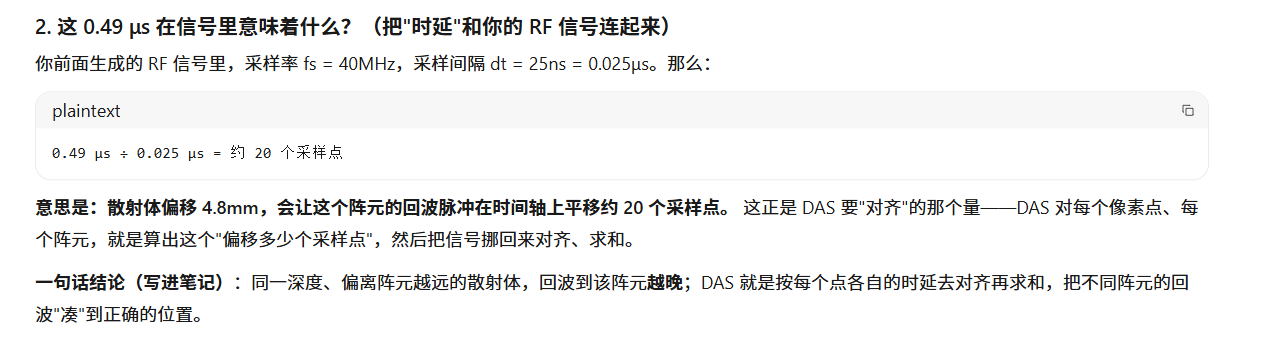